In [15]:
import pandas as pd
import yfinance as yf
from arch.unitroot import ADF, PhillipsPerron, KPSS
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [10]:
tuprs = yf.download("TUPRS.IS", period="2y", interval="1d")
Y = tuprs["Close"]

[*********************100%***********************]  1 of 1 completed


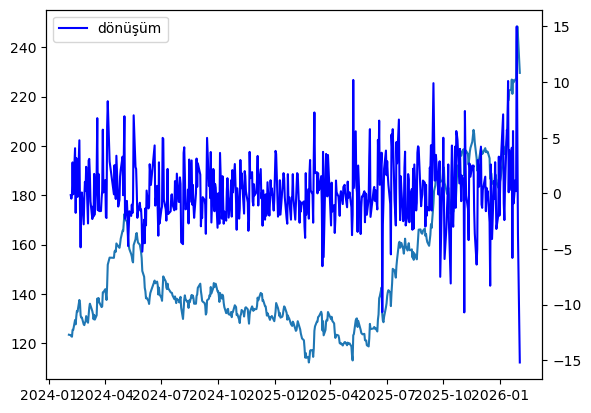

In [14]:
def birimkok(Yt):
    model=["n", "c", "ct"]
    df = pd.DataFrame(columns=["Test Adı", "Model Türü", "Gecikme", "Test İstatistiği", "Prob"])
    for i in model:
        try:
            adf = ADF(Yt, trend=i, method="aic")
            pp = PhillipsPerron(Yt, trend=i)
            kpss = KPSS(Yt, trend=i)

            df=pd.concat([
                df,
                pd.DataFrame([[adf._test_name, adf.trend, adf.lags, adf.stat, adf.pvalue]], columns=df.columns),
                pd.DataFrame([[pp._test_name, pp.trend, pp.lags, pp.stat, pp.pvalue]], columns=df.columns),
                pd.DataFrame([[kpss._test_name, kpss.trend, kpss.lags, kpss.stat, kpss.pvalue]], columns=df.columns)
            ])
           
        except ValueError:
            df=pd.concat([
                df,
                pd.DataFrame([[adf._test_name, adf.trend, adf.lags, adf.stat, adf.pvalue]], columns=df.columns),
                pd.DataFrame([[pp._test_name, pp.trend, pp.lags, pp.stat, pp.pvalue]], columns=df.columns)
            ])
    df["Model Türü"].replace({
        "n": "Sabit terimsiz ve Trendsiz",
        "c": "Sabit terimli ve Trendsiz",
        "ct": "Sabit terimli ve Trendli"}, inplace=True)
    df = df.sort_values(by="Test Adı")
    df = df.reset_index(drop=True)
    return print(df)

Ydiff = Y.diff().dropna()

fig,ax1 = plt.subplots()
ax2 = ax1.twinx()

Ylog = np.sqrt(Y)
ax1.plot(Y, label="Orijinal")
ax2.plot(Ydiff, color="b", label="dönüşüm")
plt.legend()

    

In [13]:
birimkok(Y)

                  Test Adı                  Model Türü Gecikme  \
0  Augmented Dickey-Fuller  Sabit terimsiz ve Trendsiz       3   
1  Augmented Dickey-Fuller   Sabit terimli ve Trendsiz       3   
2  Augmented Dickey-Fuller    Sabit terimli ve Trendli       3   
3   KPSS Stationarity Test   Sabit terimli ve Trendsiz      12   
4   KPSS Stationarity Test    Sabit terimli ve Trendli      12   
5     Phillips-Perron Test  Sabit terimsiz ve Trendsiz      18   
6     Phillips-Perron Test   Sabit terimli ve Trendsiz      18   
7     Phillips-Perron Test    Sabit terimli ve Trendli      18   

   Test İstatistiği      Prob  
0          1.600700  0.973416  
1          0.333451  0.978828  
2         -0.583201  0.979788  
3          1.860263  0.000100  
4          0.810893  0.000100  
5          1.605240  0.973685  
6          0.355865  0.979767  
7         -0.620350  0.977888  


C:\Users\merty\AppData\Local\Temp\ipykernel_22588\2993112333.py:8: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the old method that only depends on time, set lags=-1
  kpss = KPSS(Yt, trend=i)
C:\Users\merty\AppData\Local\Temp\ipykernel_22588\2993112333.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df=pd.concat([
C:\Users\merty\AppData\Local\Temp\ipykernel_22588\2993112333.py:8: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the old method that only depends on time, set lags=-1
  kpss = KPSS(Yt, trend=i)
C:\Users\merty\AppData\Local\Temp\ipykernel_22588\2993112333.py:8: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the

In [17]:
birimkok(Ydiff)

                  Test Adı                  Model Türü Gecikme  \
0  Augmented Dickey-Fuller  Sabit terimsiz ve Trendsiz       2   
1  Augmented Dickey-Fuller   Sabit terimli ve Trendsiz       2   
2  Augmented Dickey-Fuller    Sabit terimli ve Trendli       2   
3   KPSS Stationarity Test   Sabit terimli ve Trendsiz       4   
4   KPSS Stationarity Test    Sabit terimli ve Trendli       4   
5     Phillips-Perron Test  Sabit terimsiz ve Trendsiz      18   
6     Phillips-Perron Test   Sabit terimli ve Trendsiz      18   
7     Phillips-Perron Test    Sabit terimli ve Trendli      18   

   Test İstatistiği          Prob  
0        -13.130307  6.493874e-24  
1        -13.240613  9.187390e-25  
2        -13.316903  5.575242e-21  
3          0.291698  1.428586e-01  
4          0.085455  2.336702e-01  
5        -18.886704  3.501033e-29  
6        -18.873456  0.000000e+00  
7        -18.854904  0.000000e+00  


C:\Users\merty\AppData\Local\Temp\ipykernel_22588\1044029295.py:8: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the old method that only depends on time, set lags=-1
  kpss = KPSS(Yt, trend=i)
C:\Users\merty\AppData\Local\Temp\ipykernel_22588\1044029295.py:18: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df=pd.concat([
C:\Users\merty\AppData\Local\Temp\ipykernel_22588\1044029295.py:8: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the old method that only depends on time, set lags=-1
  kpss = KPSS(Yt, trend=i)
C:\Users\merty\AppData\Local\Temp\ipykernel_22588\1044029295.py:8: DeprecationWarning: Lag selection has changed to use a data-dependent method. To use the